## EDA для набора данных job_postings_with_salaries

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_data

df = load_data()
df_original = df.copy()

Сначала проверю, что представляет собой строка датасета: какие поля есть в записи о вакансии и что в них лежит

In [30]:
df.head()

,job_id,title,company,company_id,ats,department,location,city,region,country_code,...,url,apply_url,description,outlier_iqr_salary_min,outlier_z_salary_min,outlier_iqr_salary_max,outlier_z_salary_max,outlier_any,salary_min_winsor,salary_max_winsor
0,ace6571f01831cf0,"Instrument Engineer, On Call",Capable Labs,ashby:capable,ashby,R&D,San Francisco,San Francisco,California,US,...,https://jobs.ashbyhq.com/Capable/45d27913-0f01...,https://jobs.ashbyhq.com/Capable/45d27913-0f01...,We are a vibrant and intensely mission-driven ...,False,False,False,False,False,90000.00,340000.00
1,e94199a6a680cd58,Content Coordinator,Easygo,greenhouse:easygo,greenhouse,KICK,"Melbourne, Australia",NaN,NaN,AU,...,https://job-boards.greenhouse.io/easygo/jobs/5...,https://job-boards.greenhouse.io/easygo/jobs/5...,Are you ready to get the Easygo Edge?\n\nThis ...,False,False,False,False,False,55172.41,62068.97
2,9c804e62d2c5c251,Senior Cyber Security Engineer - Identity and ...,Latitude AI,greenhouse:latitude,greenhouse,Cybersecurity,"Pittsburgh, PA, Palo Alto, CA",NaN,NaN,NaN,...,https://job-boards.greenhouse.io/latitude/jobs...,https://job-boards.greenhouse.io/latitude/jobs...,Latitude AI (lat.ai) is building the future of...,False,False,False,False,False,160000.00,240000.00
3,425410977ee9ac0a,"Vice President, Global Accounting",Lyra Health,lever:lyrahealth,lever,G&A,United States,NaN,NaN,US,...,https://jobs.lever.co/lyrahealth/fa62dc18-6e38...,https://jobs.lever.co/lyrahealth/fa62dc18-6e38...,About Lyra Health\n\nLyra Health is a leading ...,False,False,False,False,False,213030.00,286670.00
4,cd763794ae7a598a,Platform Engineer - Workspace,Griffith University,smartrecruiters:griffithuniversity,smartrecruiters,Digital Solutions,"Nathan, QLD, Australia",Nathan,QLD,AU,...,https://jobs.smartrecruiters.com/GriffithUnive...,https://jobs.smartrecruiters.com/GriffithUnive...,Company Description\n\nEvery institution value...,False,False,False,False,False,72072.14,78082.37


In [4]:
df.tail()

,job_id,title,company,company_id,ats,department,location,city,region,country_code,...,salary_text,salary_source,salary_min_annual,salary_max_annual,posted_at,first_seen_at,language,url,apply_url,description
9168,fcc638948a996a5a,Accountant,IKO,workday:iko:iko_careers,workday,NaN,Ennis,NaN,NaN,US,...,"$74,000 – $90,000",description,74000.0,90000.0,2026-10-05T00:00:00Z,2026-10-07T05:51:50Z,NaN,https://iko.wd3.myworkdayjobs.com/IKO_Careers/...,https://iko.wd3.myworkdayjobs.com/IKO_Careers/...,IKO Industries Ltd. is a market leader in the ...
9169,fcdfece105933047,Senior Embedded Software Test Engineer,Irhythmtech,workday:irhythmtech:irhythm,workday,NaN,"Orange County, CA",NaN,NaN,US,...,"$115,000.00 - $149,000.00",description,115000.0,149000.0,2026-10-05T00:00:00Z,2026-10-07T05:38:10Z,NaN,https://irhythmtech.wd5.myworkdayjobs.com/iRhy...,https://irhythmtech.wd5.myworkdayjobs.com/iRhy...,"Career-defining. Life-changing.\n\nAt iRhythm,..."
9170,ff0c4560b3911e47,Psychiatric Mental Health Nurse Practitioner,FAU,workday:fau:fau,workday,NaN,Westgate,NaN,NaN,US,...,"$90,000 - $120,000",description,90000.0,120000.0,2026-10-05T00:00:00Z,2026-10-07T05:37:19Z,NaN,https://fau.wd1.myworkdayjobs.com/FAU/job/West...,https://fau.wd1.myworkdayjobs.com/FAU/job/West...,"Apply now to join FAU, where tomorrow begins.\..."
9171,ff15b493d7677dc9,"Medical Director, Community Medicine",ASPCA,workday:aspca:aspcawebsite,workday,NaN,"New York, NY",NaN,NaN,US,...,"$198,000 - $210,000",description,198000.0,210000.0,2026-10-05T00:00:00Z,2026-10-07T05:36:14Z,NaN,https://aspca.wd1.myworkdayjobs.com/ASPCAWebsi...,https://aspca.wd1.myworkdayjobs.com/ASPCAWebsi...,Summary:\n\nLooking for a veterinary leadershi...
9172,ffb7bc3240ab1009,Production Team Member,Silgancontainers,workday:silgancontainers:silgan,workday,NaN,"Champaign, Illinois",NaN,NaN,US,...,$17.29-$17.93,description,35963.0,37294.0,2026-10-05T00:00:00Z,2026-10-07T05:52:20Z,NaN,https://silgancontainers.wd1.myworkdayjobs.com...,https://silgancontainers.wd1.myworkdayjobs.com...,Production Team Member | Silgan Closures | Cha...


Записи довольно объёмные: одна запись содержит 27 колонок, в первых и последних строках некоторые колонки имеют значительное число пропусков, эти колонки необходимо отдельно проверить, случанойсть ли это или же паттерн самих данных.

Данные о зарплате дублируются: **salary_min** / **salary_max** — исходные значения в своей валюте и за свой период, **salary_min_annual** / **salary_max_annual** — те же суммы за год, а **salary_text** — их текстовое описание. Значит, для анализа нужно выбрать одно представление и унифицировать данные, часть информации лучше откинуть, чтобы проще было работать.

Дальше проверяю структуру самого датасета.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9173 entries, 0 to 9172
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   job_id             9173 non-null   str    
 1   title              9173 non-null   str    
 2   company            9173 non-null   str    
 3   company_id         9173 non-null   str    
 4   ats                9173 non-null   str    
 5   department         5418 non-null   str    
 6   location           9161 non-null   str    
 7   city               2386 non-null   str    
 8   region             2208 non-null   str    
 9   country_code       8051 non-null   str    
 10  workplace_type     4026 non-null   str    
 11  employment_type    6657 non-null   str    
 12  seniority          630 non-null    str    
 13  salary_min         9166 non-null   float64
 14  salary_max         9162 non-null   float64
 15  salary_currency    9173 non-null   str    
 16  salary_period      9173 non-null   

Из 27 признаков числовые только четыре, и все связанные с зарплатой: **salary_min**, **salary_max**, **salary_min_annual**, **salary_max_annual**. Остальные 23 — строковые (категориальные и текстовые).

Для категориальных считаем частоты, кардинальность и пропуски, для числовых — распределение и выбросы. Даты **posted_at** и **first_seen_at** лежат строками, для анализа по времени их придётся преобразовать в `datetime`.

In [6]:
print(df.duplicated().sum())
print("-------------------")
print(df["job_id"].duplicated().sum())
print("-------------------")
print(df.isna().sum())

0
-------------------
0
-------------------
job_id                  0
title                   0
company                 0
company_id              0
ats                     0
department           3755
location               12
city                 6787
region               6965
country_code         1122
workplace_type       5147
employment_type      2516
seniority            8543
salary_min              7
salary_max             11
salary_currency         0
salary_period           0
salary_text           177
salary_source           0
salary_min_annual       7
salary_max_annual      11
posted_at               0
first_seen_at           0
language             5679
url                     0
apply_url               0
description             0
dtype: int64


Полных дубликатов нет, **job_id** уникален — это 9173 независимые записи.

Пропусков много: например, **seniority**, **region**, **city**. **seniority** не указан, возможно из-за что указан в столбце **description** или же на сайте самой компаннии, либо же должность будет обсуждаться непосредственно на собеседовании, в любом случае с пропусками нужно что-то делать, либо удалять, либо заменять.         

Ниже — визуализация пропусков, чтобы увидеть картину целиком.

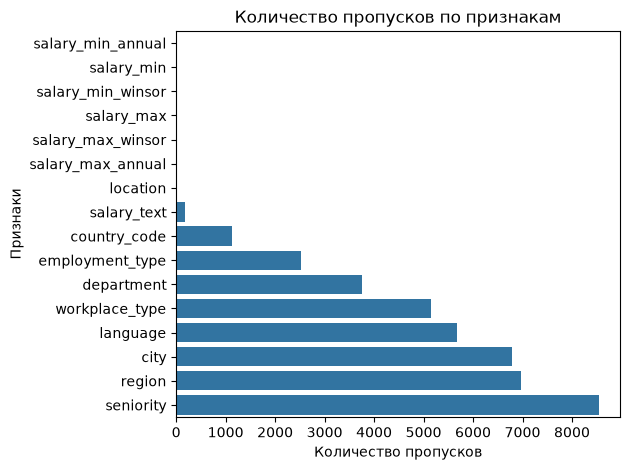

In [31]:
missing_counts = df.isna().sum().sort_values(ascending=True)
missing_counts = missing_counts[missing_counts > 0]

sns.barplot(x=missing_counts.values, y=missing_counts.index)

plt.xlabel("Количество пропусков")
plt.ylabel("Признаки")
plt.title("Количество пропусков по признакам")
plt.tight_layout()
plt.show()

Больше тысячи пропусков у восьми признаков: **seniority** (8543), **region** (6965), **city** (6787), **language** (5679), **workplace_type** (5147), **department** (3755), **employment_type** (2516), **country_code** (1122).

Зарплата указана в разных валютах (USD, EUR, CAD, GBP, AUD, PLN, NZD, CHF) и за разные периоды (год, месяц, неделя, день, час). Период обычно связан с занятостью: почасовые и частичные позиции дают ставку за час, постоянные — годовую сумму.

Необходимо изучить распределение по валютам и периодам и принять решение о том, к какому значению приводить все данные 

In [8]:
currency_counts = df["salary_currency"].value_counts()
period_counts = df["salary_period"].value_counts()

print(currency_counts)
print(period_counts)

salary_currency
USD    7796
EUR     527
CAD     499
GBP     254
AUD      57
PLN      26
NZD      10
CHF       4
Name: count, dtype: int64
salary_period
year     6639
hour     2243
month     274
week       14
day         3
Name: count, dtype: int64


По валютам доминирует **USD** — 7796 вакансий, дальше **EUR** (527) и **CAD** (499), остальные валюты единичны.

По периоду преобладает год: **year** — 6639 вакансий, но и **hour** — 2243, то есть почти четверть вакансий. Периоды **month** (274), **week** (14) и **day** (3) редки.

Поэтому нормализую к **USD** и к году — самые частые значения, значит меньше строк придётся пересчитывать.

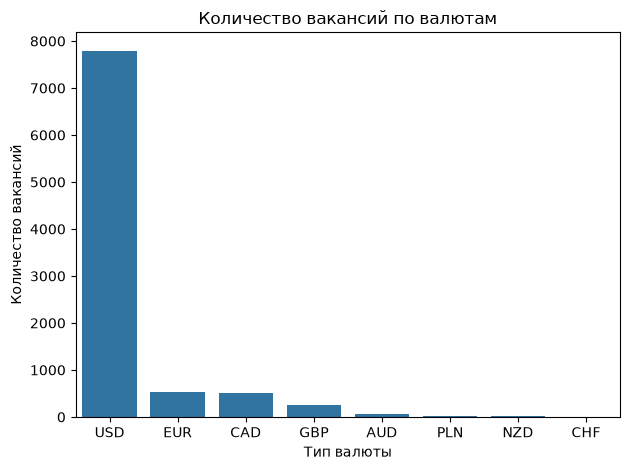

In [9]:
currency_df = currency_counts.rename('count').reset_index()
currency_df.columns = ['currency', 'count']

sns.barplot(data=currency_df, x='currency', y='count')

plt.title("Количество вакансий по валютам")
plt.xlabel("Тип валюты")
plt.ylabel("Количество вакансий")
plt.tight_layout()
plt.show()

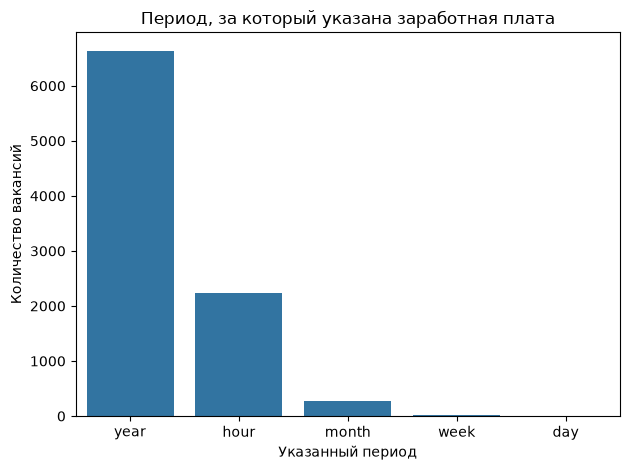

In [10]:
period_df = period_counts.rename('count').reset_index()
period_df.columns = ['period', 'count']

sns.barplot(data= period_df, x='period', y='count')

plt.title("Период, за который указана заработная плата")
plt.xlabel("Указанный период")
plt.ylabel("Количество вакансий")
plt.tight_layout()
plt.show()

Приводим зарплаты к одному виду — валюта **USD** и период «год».

Период пересчитываем через стандартное число рабочих единиц в году: час × 2080, день × 260, неделя × 52, месяц × 12, год × 1. Стандартное время по меркам американского рынка труда

In [11]:
df = df_original.copy()

dict_period_with_coef = {
    "day": 260,
    "week":52,
    "month":12,
    "hour": 2080,
    "year": 1
}

coef = df["salary_period"].map(dict_period_with_coef)
df["salary_max"] *= coef
df["salary_min"] *= coef

df['salary_period'] = df["salary_period"].replace(['day', 'week', 'hour', 'month'], 'year')


Теперь валюта: переводим суммы в **USD** по курсам Национального банка Республики Беларусь.

Коэффициенты заданы как «сколько валюты в 1 USD» (EUR 0.89, CAD 1.42, GBP 0.75, AUD 1.45, PLN 3.9, NZD 1.78, CHF 0.83), поэтому сумма делится на коэффициент: EUR 59 175 → ≈66 489 USD.

Курс зафиксирован на одну дату, так что пересчёт приблизительный, но для сравнения порядков этого достаточно.

In [12]:
dict_currency_with_coef = {
    "USD": 1.0,
    "EUR": 0.89,
    "CAD": 1.42,
    "GBP": 0.75,
    "AUD": 1.45,
    "PLN": 3.9,
    "NZD": 1.78,
    "CHF": 0.83
}

coef_currency = df["salary_currency"].map(dict_currency_with_coef)


df["salary_max"] = (df["salary_max"] / coef_currency).round(2)
df["salary_min"] = (df["salary_min"] / coef_currency).round(2)

df['salary_currency'] = df["salary_currency"].replace(['EUR', 'CAD', 'GBP', 'AUD', 'PLN', 'NZD', 'CHF'], 'USD')

In [13]:
df.describe().round(2)

,salary_min,salary_max,salary_min_annual,salary_max_annual
count,9166.00,9162.00,9166.00,9162.00
mean,100549.07,133027.04,101631.87,134440.04
std,69469.52,93543.36,68762.03,92838.37
min,2051.28,2564.10,8000.00,9000.00
25%,52000.00,66666.67,52202.00,68640.00
50%,85000.00,112379.78,86000.00,115000.00
75%,130939.44,178880.00,133950.00,180000.00
max,1168539.33,1380000.00,1104000.00,1380000.00


Курсы взяты на 15.10.2026 по данным НБ Республики Беларусь. Это статические значения, а не исторические: при обновлении данных их стоит перепроверять

После нормализации **salary_currency** и **salary_period** стали константами (USD, year) и для анализа больше не нужны. А два оставшихся признака стоит посмотреть:

- **salary_text** — исходное описание зарплаты, дублирует числовые колонки, но удобен как проверка корректности пересчёта;
- **salary_source** — откуда взята зарплата (поле ATS или текст описания), потенциально полезный категориальный признак.

Проверяю 20 случайных записей и сопоставляю **salary_text** с посчитанными **salary_min** / **salary_max**: расхождения сразу показывают проблемные строки.

In [14]:
salary_cols = [
    "salary_min",
    "salary_max",
    "salary_currency",
    "salary_period",
    "salary_text",
    "salary_source",
    "salary_min_annual",
    "salary_max_annual"
]

df[salary_cols].sample(
    n = 20,
    random_state=42
)

,salary_min,salary_max,salary_currency,salary_period,salary_text,salary_source,salary_min_annual,salary_max_annual
624,75000.00,90000.00,USD,year,"$75,000 - $90,000",description,75000.0,90000.0
6458,160000.00,240000.00,USD,year,$160K - $240K,ats,160000.0,240000.0
3128,104800.00,157200.00,USD,year,"$104,800.00 - $157,200.00",description,104800.0,157200.0
5501,75000.00,105300.00,USD,year,$75K - $105.3K,ats,75000.0,105300.0
9071,80000.00,93000.00,USD,year,"$80,000 - $93,000",description,80000.0,93000.0
3298,66488.76,110814.61,USD,year,"EUR 59,175 to EUR 98,625",description,59175.0,98625.0
2664,240000.00,240000.00,USD,year,$240K,ats,240000.0,240000.0
5810,130000.00,250000.00,USD,year,"$130,000-$250,000",description,130000.0,250000.0
5504,35360.00,35360.00,USD,year,17.00 USD per hour,ats,35360.0,35360.0
5274,46000.00,54000.00,USD,year,"$46,000 – $54,000 USD",description,46000.0,54000.0


In [15]:
print(df['salary_currency'].value_counts())
print("-------------------------")
print(df['salary_period'].value_counts())
print("-------------------------")
print(df['salary_source'].value_counts())

salary_currency
USD    9173
Name: count, dtype: int64
-------------------------
salary_period
year    9173
Name: count, dtype: int64
-------------------------
salary_source
description    6060
ats            3113
Name: count, dtype: int64


Итог по этим признакам:

- **salary_text** — то же описание зарплаты, что уже посчитано в **salary_min** / **salary_max**. Для анализа не нужен, но полезен как контроль: по нему видно, где пересчёт сработал неверно.
- **salary_currency** и **salary_period** стали константами и больше не участвуют.
- **salary_source** — полезный признак: показывает, откуда взялась зарплата, и косвенно характеризует компанию и способ сбора данных. Разбираем его дальше вместе с другими категориальными признаками.

## Взаимосвязь категориальных признаков и заработной платы

Сравниваю категориальные признаки с **salary_min** и **salary_max** — уже приведёнными к USD и году. В таблицах: **n** — число вакансий, **min_median** / **max_median** — медианы, **median_vs_all** — отношение медианы категории к общей медиане.

Зарплаты сильно смещены вправо (skew ≈ 3.8), поэтому смотрим медиану и квартили, а не среднее. В расчёт попадают только категории с **n ≥ 30**, а пропуски выделены как «(нет данных)». На boxplot'ах выбросы скрыты — им посвящён следующий раздел.

Сначала общая картина: сколько уникальных значений и пропусков в каждом признаке. От этого зависит, что вообще имеет смысл сравнивать по группам.

In [16]:
overview = pd.DataFrame({
    "уникальных значений": df.nunique(dropna=True),
    "пропусков": df.isna().sum(),
    "доля пропусков, %": (df.isna().mean() * 100).round(1),
    "тип": df.dtypes.astype(str),
}).sort_values("уникальных значений", ascending=False)

display(overview)

,уникальных значений,пропусков,"доля пропусков, %",тип
job_id,9173,0,0.0,str
apply_url,9171,0,0.0,str
url,9171,0,0.0,str
description,8943,0,0.0,str
title,8044,0,0.0,str
salary_text,6973,177,1.9,str
posted_at,5751,0,0.0,str
first_seen_at,5439,0,0.0,str
location,4372,12,0.1,str
company_id,4175,0,0.0,str


In [17]:
MISSING_LABEL = "(нет данных)"
MIN_GROUP_SIZE = 30


def salary_stats_by_category(data, column, min_n=MIN_GROUP_SIZE):
    prepared = data.copy()
    prepared[column] = prepared[column].fillna(MISSING_LABEL)

    stats = (
        prepared.groupby(column)
        .agg(
            n=("salary_min", "size"),
            min_median=("salary_min", "median"),
            max_median=("salary_max", "median"),
            min_q1=("salary_min", lambda values: values.quantile(0.25)),
            min_q3=("salary_min", lambda values: values.quantile(0.75)),
        )
        .sort_values("min_median", ascending=False)
    )
    stats["median_vs_all"] = (stats["min_median"] / data["salary_min"].median()).round(2)

    result = stats[stats["n"] >= min_n].copy()
    salary_columns = ["min_median", "max_median", "min_q1", "min_q3"]
    result[salary_columns] = result[salary_columns].round(0)

    return result


def plot_salary_by_category(data, column, min_n=MIN_GROUP_SIZE):
    prepared = data.copy()
    prepared[column] = prepared[column].fillna(MISSING_LABEL)

    counts = prepared[column].value_counts()
    prepared = prepared[prepared[column].isin(counts[counts >= min_n].index)]
    order = prepared.groupby(column)["salary_min"].median().sort_values(ascending=False).index

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax, salary_col in zip(axes, ["salary_min", "salary_max"]):
        sns.boxplot(data=prepared, x=column, y=salary_col, order=order, ax=ax, showfliers=False)
        ax.axhline(data[salary_col].median(), color="red", linestyle="--", linewidth=1)
        ax.set_title(f"{salary_col} по признаку {column}")
        ax.set_xlabel("")
        ax.set_ylabel("USD в год")
        ax.tick_params(axis="x", rotation=40)

    plt.tight_layout()
    plt.show()

У признаков с высокой кардинальностью (**title** — 8044, **location** — 4372, **company** — 3970, **department** — 2213, **city** — 800) почти каждая категория встречается один раз, поэтому напрямую по группам их не сравниваю — нужна агрегация (роль из title, отрасль из department).

Для сравнения берём признаки с разумным числом категорий: **ats**, **employment_type**, **workplace_type**, **seniority**, **salary_source**, **country_code**.

**ats** — платформа вакансии. Косвенно показывает тип компаний: через Ashby публикуются в основном стартапы, через Workday — крупный корпоративный сектор.

,n,min_median,max_median,min_q1,min_q3,median_vs_all
ats,,,,,,
ashby,1560,130000.0,170500.0,83200.0,172347.0,1.53
greenhouse,2905,100000.0,130000.0,64800.0,150000.0,1.18
lever,86,75953.0,100000.0,45798.0,117500.0,0.89
workday,3330,70423.0,95039.0,46800.0,105000.0,0.83
breezy,464,62400.0,78451.0,41600.0,90000.0,0.73
smartrecruiters,561,60000.0,76960.0,41600.0,100000.0,0.71
teamtailor,75,47191.0,66667.0,34472.0,66208.0,0.56
recruitee,161,44811.0,61196.0,35955.0,58598.0,0.53


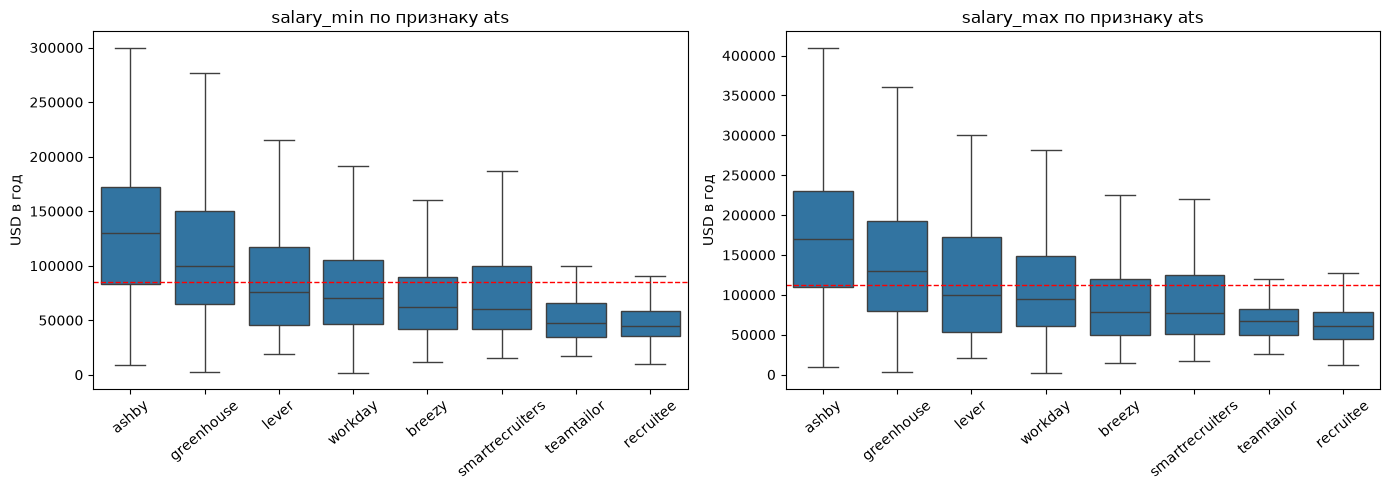

In [18]:
display(salary_stats_by_category(df, "ats"))
plot_salary_by_category(df, "ats")

**employment_type** — тип занятости. Ожидаемо ниже всего part-time и temporary, выше всего full-time.

,n,min_median,max_median,min_q1,min_q3,median_vs_all
employment_type,,,,,,
(нет данных),2516,103654.0,133049.0,65000.0,150000.0,1.22
full-time,5868,84892.0,114400.0,53778.0,130000.0,1.00
contract,124,72000.0,90255.0,41600.0,114400.0,0.85
other,63,59646.0,83200.0,37482.0,95850.0,0.70
internship,53,52000.0,58240.0,37856.0,80512.0,0.61
temporary,104,47840.0,64293.0,38272.0,73389.0,0.56
part-time,442,37440.0,47840.0,33114.0,52000.0,0.44


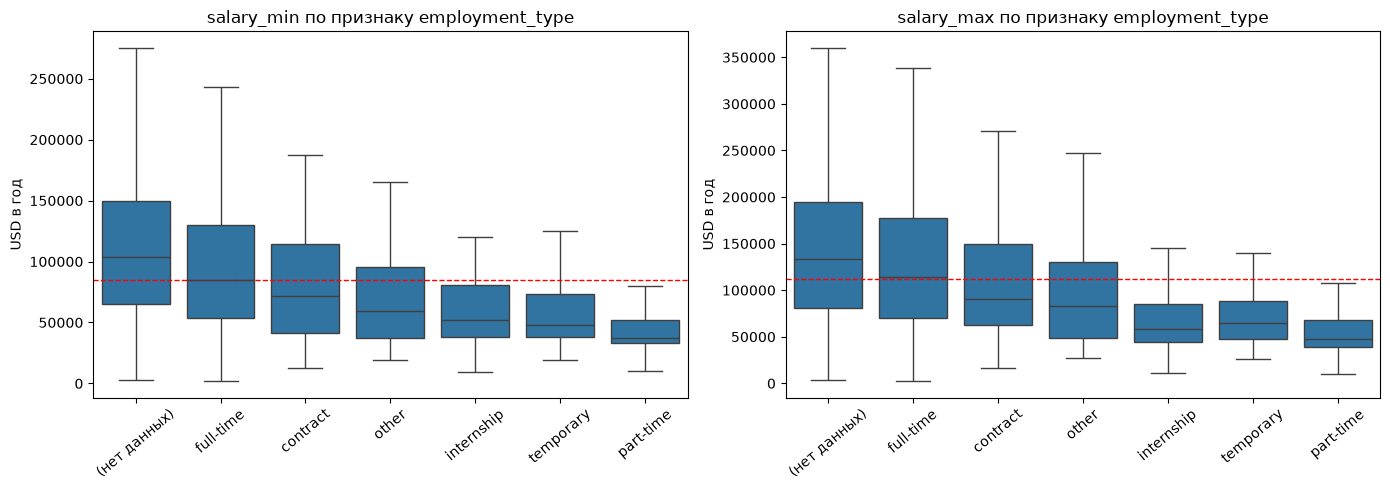

In [19]:
display(salary_stats_by_category(df, "employment_type"))
plot_salary_by_category(df, "employment_type")

**workplace_type** — формат работы. Проверяем расхожее мнение, что на remote платят больше, чем onsite.

,n,min_median,max_median,min_q1,min_q3,median_vs_all
workplace_type,,,,,,
remote,1731,110000.0,150000.0,75000.0,150000.0,1.29
hybrid,1031,100000.0,133000.0,66515.0,156000.0,1.18
(нет данных),5147,76700.0,100000.0,49296.0,120000.0,0.90
onsite,1264,66667.0,85953.0,41600.0,120320.0,0.78


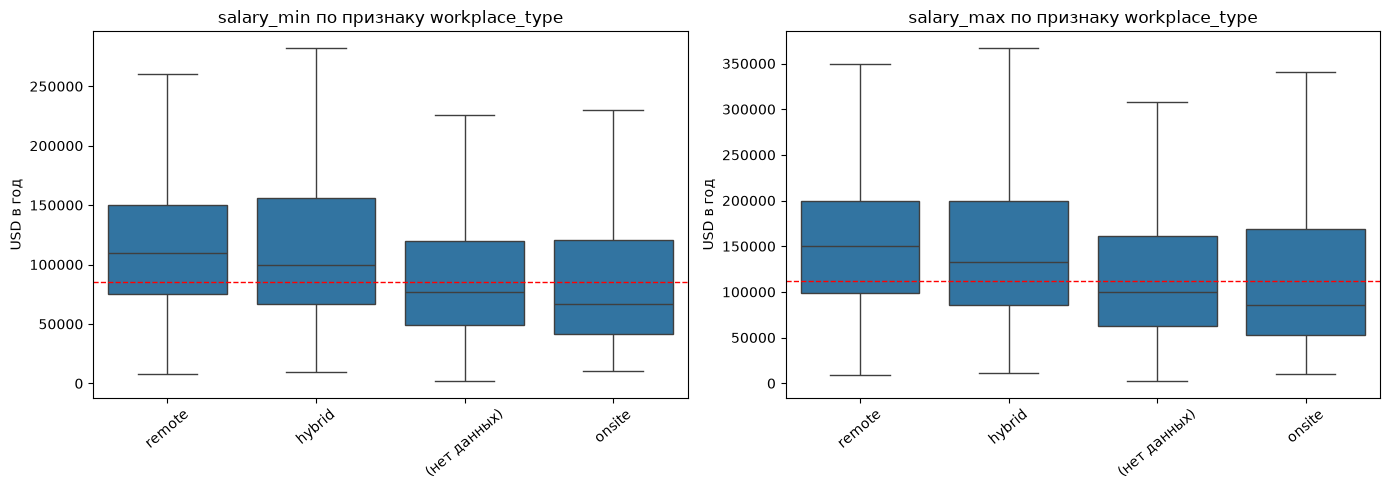

In [20]:
display(salary_stats_by_category(df, "workplace_type"))
plot_salary_by_category(df, "workplace_type")

**seniority** — уровень позиции. Признак заполнен плохо (около 630 значений), поэтому здесь порог снижен до n ≥ 20, чтобы попала группа executive (24 наблюдения). Internship (15) всё равно отсеивается.

,n,min_median,max_median,min_q1,min_q3,median_vs_all
seniority,,,,,,
executive,24,100000.0,154108.0,75965.0,160000.0,1.18
(нет данных),8543,88000.0,116197.0,54080.0,135000.0,1.04
senior,209,83200.0,104000.0,56180.0,125000.0,0.98
mid,107,50711.0,69000.0,40102.0,67416.0,0.60
entry,275,44860.0,54510.0,35962.0,60586.0,0.53


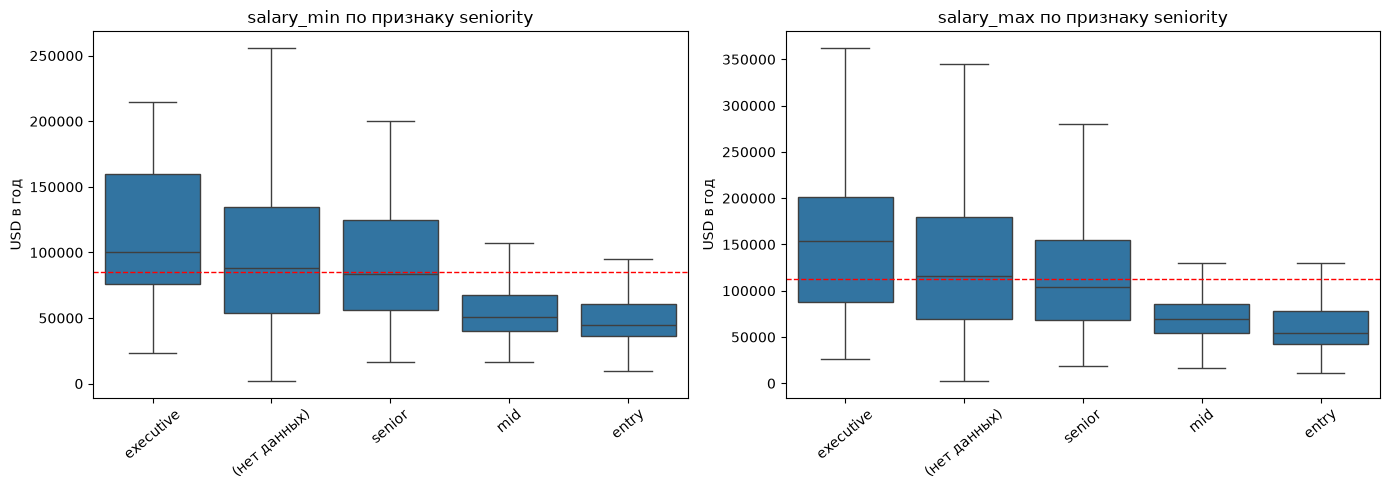

In [21]:
display(salary_stats_by_category(df, "seniority", min_n=20))
plot_salary_by_category(df, "seniority", min_n=20)

**salary_source** — откуда взята зарплата: из поля ATS или из текста вакансии. Разные источники по-разному указывают период и валюту, поэтому часть различий — следствие сбора данных, а не рынка.

,n,min_median,max_median,min_q1,min_q3,median_vs_all
salary_source,,,,,,
ats,3113,100000.0,130000.0,60000.0,150000.0,1.18
description,6060,80000.0,104500.0,50000.0,120000.0,0.94


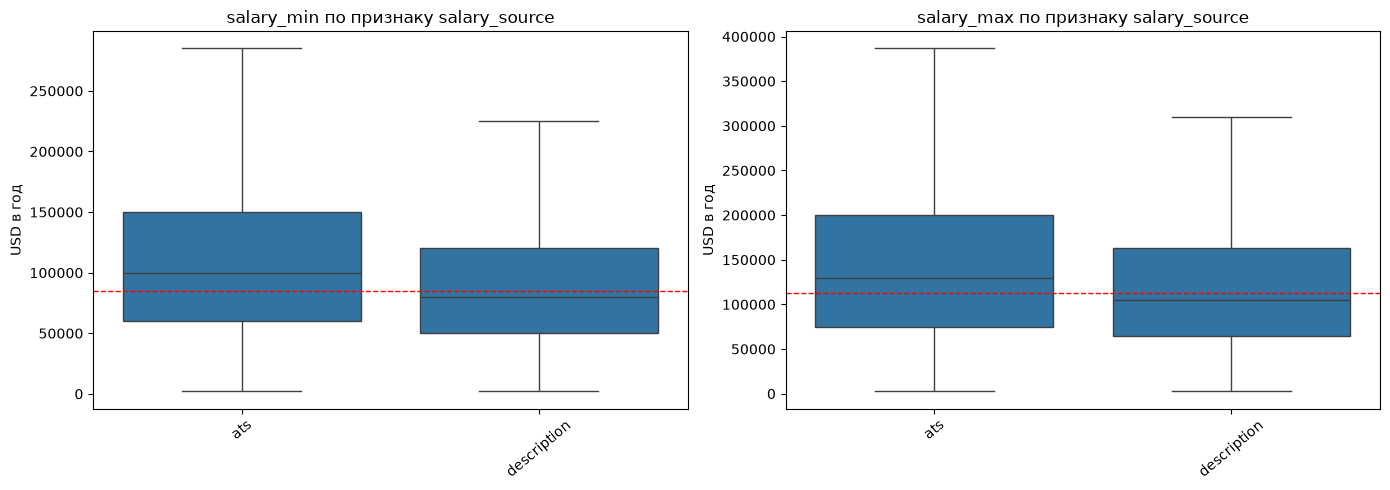

In [22]:
display(salary_stats_by_category(df, "salary_source"))
plot_salary_by_category(df, "salary_source")

**country_code** — страна вакансии. В расчёт попадают только страны с n ≥ 30.

,n,min_median,max_median,min_q1,min_q3,median_vs_all
country_code,,,,,,
(нет данных),1122,110000.0,142082.0,70000.0,156000.0,1.29
US,6622,90000.0,121465.0,56557.0,136190.0,1.06
AU,54,72336.0,82720.0,55262.0,83321.0,0.85
DE,75,65730.0,84831.0,40449.0,91011.0,0.77
GB,240,60000.0,75177.0,42740.0,93333.0,0.71
CA,538,54930.0,70423.0,37458.0,76585.0,0.65
NL,107,50099.0,70746.0,38939.0,62899.0,0.59
FR,101,35955.0,43921.0,28090.0,49438.0,0.42
IT,77,35955.0,50562.0,31461.0,48989.0,0.42


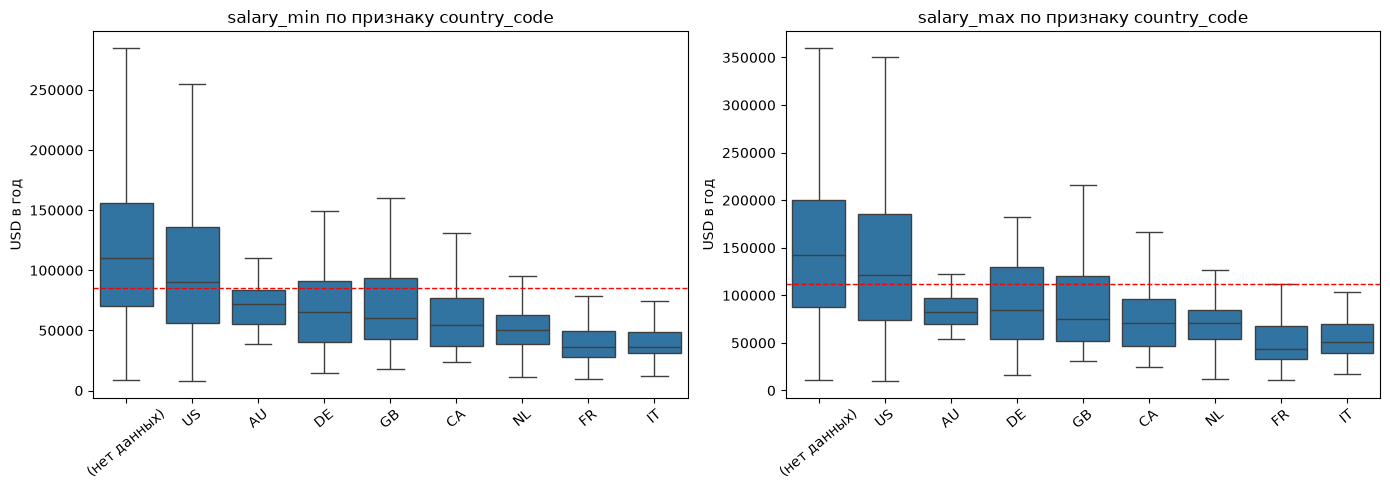

In [23]:
display(salary_stats_by_category(df, "country_code"))
plot_salary_by_category(df, "country_code")

**language** и **region** отдельно не разбираем: у language с n ≥ 30 остаётся только `en` (3389), остальные группы по 1–35 наблюдений, а region — 244 значения с очень неравномерным заполнением.

### Итоги по категориальным признакам

- **ats** — самый заметный признак: медиана salary_min от 44 811 (Recruitee) до 130 000 (Ashby), почти в 3 раза. Для salary_max картина та же: 61 196 против 170 500.
- **workplace_type** — remote (110 000) > hybrid (100 000) > onsite (66 667); «нет данных» (76 700) между onsite и hybrid.
- **employment_type** — full-time 84 892, part-time 37 440 (в 2.3 раза меньше), temporary 47 840; contract (72 000) ниже full-time. Группы contract/temporary/internship небольшие (124 / 104 / 53).
- **seniority** — порядок ожидаемый: executive 100 000 > senior 83 200 > mid 50 711 > entry 44 860. Признак сильный, но 93% пропусков, так что его нужно восстанавливать из title.
- **country_code** — среди стран с n ≥ 30 выше всех США (90 000), ниже всех Франция и Италия (~36 000). При этом группа «нет данных» (110 000) выше всех стран: отсутствие страны связано с более высокими зарплатами.
- **salary_source** — ats 100 000 против description 80 000, и доля выбросов в ats-выборке выше (4.4% против 2.8%).

Пропуски образуют большие отдельные категории (workplace_type 56%, seniority 93%, language 62%), и это не случайная подвыборка — у них своя медиана и свои платформы-источники. Значимость различий проверяем отдельно, в `hypothesis_testing.ipynb`.

## Числовые выбросы

Числовых признаков четыре: **salary_min**, **salary_max**, **salary_min_annual**, **salary_max_annual**. Разница в том, что `annual`-колонки приведены к году, но **без пересчёта валюты**, а `salary_min` / `salary_max` — и к году, и к USD. Поэтому основными берём последние, а annual показываем рядом для сравнения.

Ищем выбросы двумя способами: по **межквартильному размаху (Тьюки)** — границы `Q1 − 1.5·IQR` и `Q3 + 1.5·IQR`, и по **z-оценке** (|z| > 3). Первый устойчив к асимметрии, второй даёт более строгий фильтр.

Удалять такие строки сразу нельзя — часть из них настоящие высокие зарплаты, поэтому сначала смотрим квантили, потом разбираем причины.

In [24]:
salary_cols = ["salary_min", "salary_max", "salary_min_annual", "salary_max_annual"]

quantile_levels = [0.0, 0.001, 0.005, 0.01, 0.05, 0.5, 0.95, 0.99, 0.995, 0.999, 1.0]

quantile_table = df[salary_cols].quantile(quantile_levels).round(0)
quantile_table.loc["mean"] = df[salary_cols].mean().round(0)
quantile_table.loc["std"] = df[salary_cols].std().round(0)
quantile_table.loc["skew"] = df[salary_cols].skew().round(2)
quantile_table.loc["mean / median"] = (df[salary_cols].mean() / df[salary_cols].median()).round(2)

display(quantile_table)

,salary_min,salary_max,salary_min_annual,salary_max_annual
0.0,2051.00,2564.00,8000.00,9000.00
0.001,10466.00,11461.00,10792.00,10993.00
0.005,16640.00,24000.00,15509.00,22730.00
0.01,22187.00,29120.00,20800.00,27000.00
0.05,33280.00,39005.00,32240.00,38834.00
0.5,85000.00,112380.00,86000.00,115000.00
0.95,210000.00,289876.00,212000.00,291185.00
0.99,304000.00,405039.00,304700.00,405600.00
0.995,380000.00,500000.00,380437.00,500000.00
0.999,720000.00,1010715.00,720000.00,960000.00


По квантилям проблема видна сразу: медиана salary_min — 85 000, максимум — 1 168 539 (в 13.7 раза больше), у salary_max — 112 380 против 1 380 000. Асимметрия 3.4–3.8, среднее к медиане 1.18.

Ещё любопытно расхождение минимумов: у `salary_min` минимум 2 051 (польская вакансия в злотых), а у `salary_min_annual` — 8 000, потому что annual-колонки не пересчитаны в валюту.

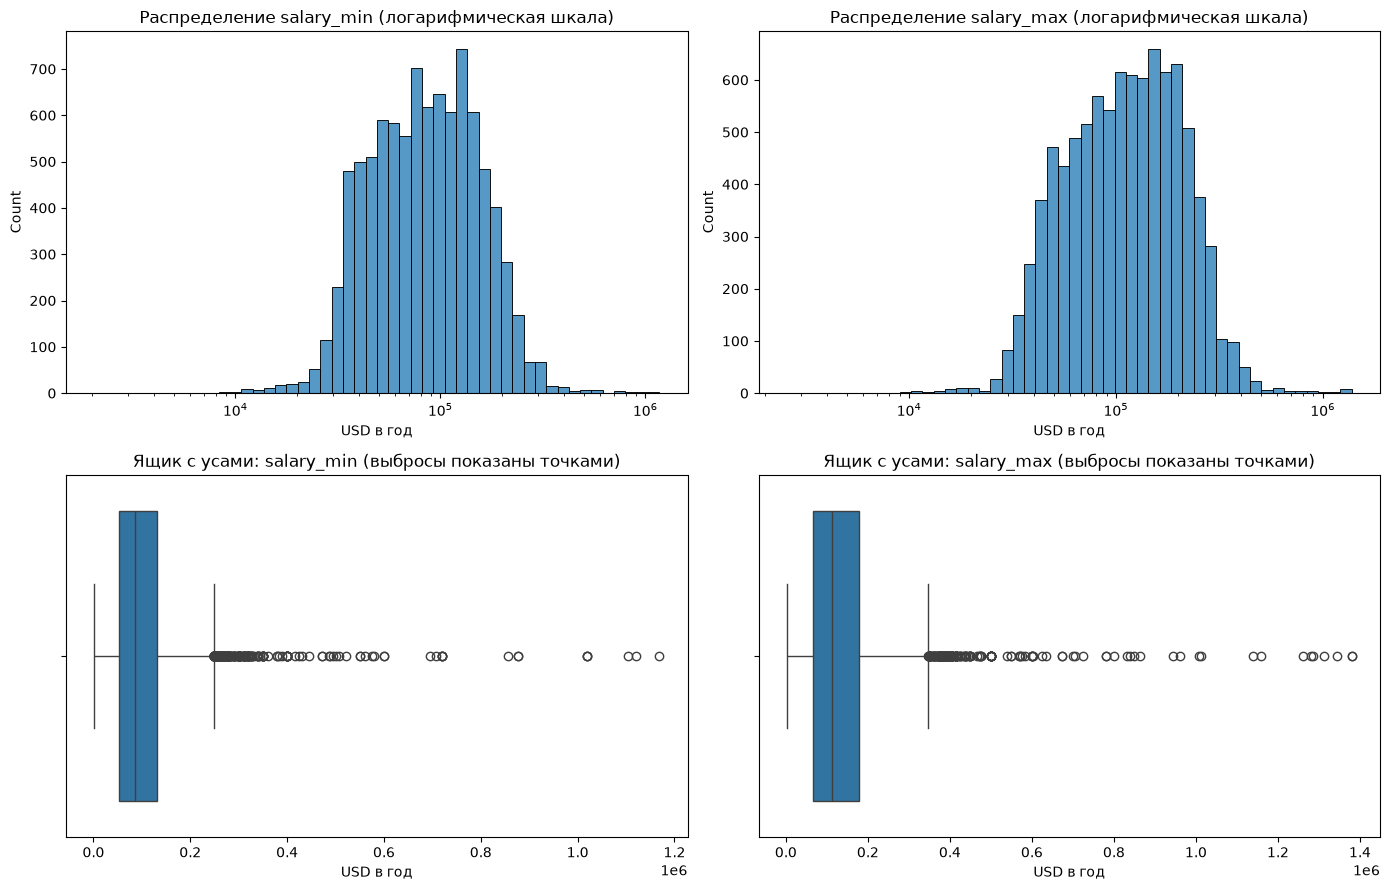

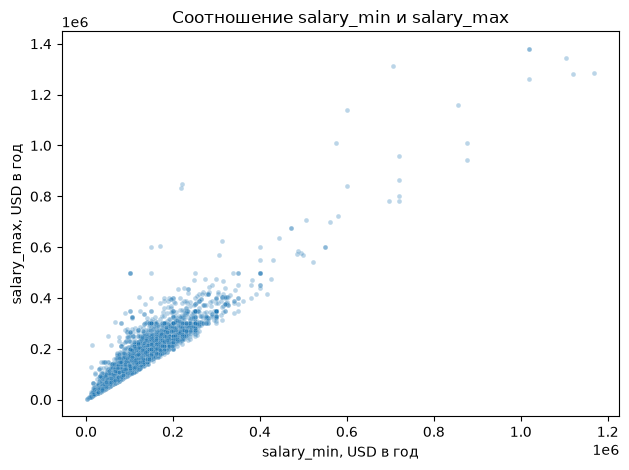

Корреляция salary_min и salary_max:


,salary_min,salary_max
salary_min,1.000,0.944
salary_max,0.944,1.000


,salary_min,salary_max
salary_min,1.000,0.958
salary_max,0.958,1.000


In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, salary_col in zip(axes[0], ["salary_min", "salary_max"]):
    sns.histplot(df[salary_col].dropna(), bins=50, log_scale=True, ax=ax)
    ax.set_title(f"Распределение {salary_col} (логарифмическая шкала)")
    ax.set_xlabel("USD в год")

for ax, salary_col in zip(axes[1], ["salary_min", "salary_max"]):
    sns.boxplot(x=df[salary_col].dropna(), ax=ax)
    ax.set_title(f"Ящик с усами: {salary_col} (выбросы показаны точками)")
    ax.set_xlabel("USD в год")

plt.tight_layout()
plt.show()

sns.scatterplot(data=df, x="salary_min", y="salary_max", alpha=0.3, s=12)
plt.title("Соотношение salary_min и salary_max")
plt.xlabel("salary_min, USD в год")
plt.ylabel("salary_max, USD в год")
plt.tight_layout()
plt.show()

print("Корреляция salary_min и salary_max:")
display(df[["salary_min", "salary_max"]].corr(method="pearson").round(3))
display(df[["salary_min", "salary_max"]].corr(method="spearman").round(3))

Гистограмма подтверждает длинный правый хвост, а на boxplot'ах видно, что выбросы только сверху: нижняя граница Тьюки уходит в минус, так что формально «нижних» выбросов нет.

salary_min и salary_max движутся вместе — корреляция 0.944 (Pearson) и 0.958 (Spearman), так что анализировать их можно одинаково.

In [26]:
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


outlier_report = []

for salary_col in ["salary_min", "salary_max"]:
    values = df[salary_col]
    low, high = iqr_bounds(values.dropna())
    z_scores = (values - values.mean()) / values.std()

    df[f"outlier_iqr_{salary_col}"] = (values < low) | (values > high)
    df[f"outlier_z_{salary_col}"] = z_scores.abs() > 3

    outlier_report.append({
        "признак": salary_col,
        "нижняя граница (IQR)": round(low),
        "верхняя граница (IQR)": round(high),
        "ниже нижней границы": int((values < low).sum()),
        "выше верхней границы": int((values > high).sum()),
        "|z| > 3": int((z_scores.abs() > 3).sum()),
        "|z| > 4": int((z_scores.abs() > 4).sum()),
    })

df["outlier_any"] = df["outlier_iqr_salary_min"] | df["outlier_iqr_salary_max"]

display(pd.DataFrame(outlier_report).set_index("признак"))
print("Строк, где зарплата выходит за границы IQR хотя бы по одному признаку:", int(df["outlier_any"].sum()))

,нижняя граница (IQR),верхняя граница (IQR),ниже нижней границы,выше верхней границы,|z| > 3,|z| > 4
признак,,,,,,
salary_min,-66409,249349,0,250,90,47
salary_max,-101653,347200,0,206,85,40


Строк, где зарплата выходит за границы IQR хотя бы по одному признаку: 307


По Тьюки выбросов сверху ~250 для salary_min и ~206 для salary_max (2.7% и 2.2% наблюдений), по z-оценке строже — 90 и 85. Нижних выбросов нет ни у одного признака.

Теперь главный вопрос: это реальные зарплаты или ошибки пересчёта? Посмотрим сами строки вместе с исходными значениями и текстом.

In [27]:
outlier_rows = df[df["outlier_iqr_salary_min"]].copy()
outlier_rows["raw_min"] = df_original.loc[outlier_rows.index, "salary_min"]
outlier_rows["raw_max"] = df_original.loc[outlier_rows.index, "salary_max"]
outlier_rows["raw_period"] = df_original.loc[outlier_rows.index, "salary_period"]
outlier_rows["raw_currency"] = df_original.loc[outlier_rows.index, "salary_currency"]

columns_to_show = [
    "title",
    "salary_text",
    "raw_min",
    "raw_max",
    "raw_period",
    "raw_currency",
    "salary_min",
    "salary_max",
    "salary_source",
    "country_code",
]

display(outlier_rows.sort_values("salary_min", ascending=False)[columns_to_show].head(15))

,title,salary_text,raw_min,raw_max,raw_period,raw_currency,salary_min,salary_max,salary_source,country_code
4936,HR Intern - Talent & Leadership Development,€500-550,500.0,550.0,hour,EUR,1168539.33,1285393.26,description,NL
386,Global Revenue Marketing Manager,"70,000 GBP- 80,000 GBP",70000.0,80000.0,month,GBP,1120000.00,1280000.00,description,GB
5336,BCBA,"$92,000 – 112,000",92000.0,112000.0,month,USD,1104000.00,1344000.00,description,US
5264,Physical Therapist Clinic Director,"$85,000 - $105,000",85000.0,105000.0,month,USD,1020000.00,1260000.00,description,US
5442,Board Certified Behavior Analyst (BCBA),"$85,000–$115,000",85000.0,115000.0,month,USD,1020000.00,1380000.00,description,US
2640,Board Certified Behavior Analyst (BCBA),"$85,000–$115,000",85000.0,115000.0,month,USD,1020000.00,1380000.00,description,US
2911,Manager EHS (m/w/d),65.000-75.000€,65000.0,75000.0,month,EUR,876404.49,1011235.96,description,DE
393,Global Revenue Marketing Manager,"65,000 EUR - 70,000 EUR",65000.0,70000.0,month,EUR,876404.49,943820.22,description,ES
4721,"Faculty, Occupational Therapy Assistant","$71,270 - $96,596",71270.0,96596.0,month,USD,855240.00,1159152.00,description,US
1768,Education Administration and Supervision Teach...,"$60,000-$72,000",60000.0,72000.0,month,USD,720000.00,864000.00,description,US


Первые строки — как раз ошибки нормализации: в **salary_text** указана годовая сумма (`$85,000–$115,000`, `€500-550`), но период помечен как `month` или `hour`, и после умножения получается 1.0–1.4 млн. Проверим, насколько это системно.

In [28]:
df_work = df.copy()
df_work["raw_period"] = df_original["salary_period"]
df_work["outlier_label"] = df_work["outlier_any"].map({True: "выброс", False: "остальные"})

period_share = (
    pd.crosstab(df_work["raw_period"], df_work["outlier_label"], normalize="index")
    .mul(100)
    .round(1)
)
period_share["всего вакансий"] = df_work["raw_period"].value_counts()

source_share = (
    pd.crosstab(df_work["salary_source"], df_work["outlier_label"], normalize="index")
    .mul(100)
    .round(1)
)
source_share["всего вакансий"] = df_work["salary_source"].value_counts()

display(period_share)
display(source_share)

print("Выбросов по salary_min:", int(df["outlier_iqr_salary_min"].sum()))
print("Выбросов по salary_max:", int(df["outlier_iqr_salary_max"].sum()))
print("Выбросов хотя бы по одному признаку:", int(df["outlier_any"].sum()))
print(
    "Из них с исходным периодом, отличным от года:",
    int((df["outlier_any"] & (df_original["salary_period"] != "year")).sum()),
)

outlier_label,выброс,остальные,всего вакансий
raw_period,,,
day,0.0,100.0,3
hour,0.9,99.1,2243
month,7.7,92.3,274
week,14.3,85.7,14
year,4.0,96.0,6639


outlier_label,выброс,остальные,всего вакансий
salary_source,,,
ats,4.4,95.6,3113
description,2.8,97.2,6060


Выбросов по salary_min: 250
Выбросов по salary_max: 206
Выбросов хотя бы по одному признаку: 307
Из них с исходным периодом, отличным от года: 43


Среди вакансий с периодом `month` в выбросы попадает 7.7% (21 из 274) — почти вдвое больше, чем при годовом периоде (4.0%). А у `hour` доля минимальна (0.9%): почасовые ставки после умножения на 2080 обычно попадают в нормальный диапазон.

Так что выбросы делятся на три группы:

1. **Ошибки периода** (~43 строки из 307) — в тексте годовая сумма, а период помечен как `month` или `hour`. Это ошибка данных, а не рынка.
2. **Реально высокие зарплаты** — 99.5-й квантиль salary_min 380 000, 99.9-й — 720 000 (senior и руководящие позиции в США). Естественный хвост, убирать его нельзя.
3. **Низкий хвост** — почасовые и part-time вакансии (`$5.00/hour`, `$700/month`) и зарплаты в злотых (~2 051 USD/год). По IQR это не выбросы, но в шкале USD/год они сильно тянут вниз.

Поэтому «просто отрезать всё выше 250 000» — плохое решение: вместе с ошибками уйдут реальные высокие зарплаты. Лучше пометить строки флагами и завести сглаженные колонки.

In [29]:
winsor_bounds = {}

for salary_col in ["salary_min", "salary_max"]:
    low, high = df[salary_col].quantile([0.01, 0.99])
    winsor_bounds[salary_col] = (round(low), round(high))
    df[f"{salary_col}_winsor"] = df[salary_col].clip(low, high)

winsor_compare = pd.DataFrame(
    {
        "было: среднее": df[["salary_min", "salary_max"]].mean().round(0).to_numpy(),
        "стало: среднее": df[["salary_min_winsor", "salary_max_winsor"]].mean().round(0).to_numpy(),
        "было: стандартное отклонение": df[["salary_min", "salary_max"]].std().round(0).to_numpy(),
        "стало: стандартное отклонение": df[["salary_min_winsor", "salary_max_winsor"]].std().round(0).to_numpy(),
        "изменено значений": [
            int((df["salary_min"] != df["salary_min_winsor"]).sum()),
            int((df["salary_max"] != df["salary_max_winsor"]).sum()),
        ],
    },
    index=["salary_min", "salary_max"],
)

print("Границы winsorization (1% и 99% квантили):", winsor_bounds)
display(winsor_compare)

Границы winsorization (1% и 99% квантили): {'salary_min': (22187, 304000), 'salary_max': (29120, 405039)}


,было: среднее,стало: среднее,было: стандартное отклонение,стало: стандартное отклонение,изменено значений
salary_min,100549.0,98987.0,69470.0,58624.0,189
salary_max,133027.0,130979.0,93543.0,80093.0,192


### Что сделано с выбросами

Строки не удаляются — иначе потеряем реальные высокие зарплаты. Вместо этого добавлены:

- флаги **`outlier_iqr_salary_min`**, **`outlier_iqr_salary_max`**, **`outlier_z_salary_min`**, **`outlier_z_salary_max`** и общий **`outlier_any`**;
- сглаженные колонки **`salary_min_winsor`** и **`salary_max_winsor`** (обрезка по 1% и 99% квантилям): среднее почти не меняется, а стандартное отклонение падает с 69 470 до 58 624 и с 93 543 до 80 093.

Как использовать: для описательных статистик — winsorized-колонки, для моделей — исходные значения плюс флаг `outlier_any`, а ≈43 строки с подозрительным `salary_period` стоит перепроверить отдельно.

## Общий вывод

1. **Категориальные признаки.** Сильнее всего с зарплатой связаны **ats** (медиана от 44 811 до 130 000), **seniority** (entry 44 860 → executive 100 000, но 93% пропусков), **workplace_type** (remote 110 000 против onsite 66 667), **employment_type** (part-time 37 440 против full-time 84 892) и **country_code** (лидируют США, 90 000). Признаки с высокой кардинальностью (title, company, department, city) сначала нужно агрегировать.

2. **Числовые выбросы.** Распределение зарплат сильно смещено вправо (skew ≈ 3.8), выбросы только сверху: ~250 строк по salary_min и ~206 по salary_max по Тьюки, 90 и 85 по z-оценке. Большинство — реальные высокие зарплаты, но ≈43 строки появились из-за неверно указанного `salary_period`. Обработано флагами и winsorization, без удаления строк.